You are a data analyst working for a tech company closely monitoring the AI tools market. You want to understand the evolving popularity of three major AI tools, ChatGPT, Gemini, and Microsoft Copilot, and identify which tool is gaining the most traction and how they compare over time.


<img src="ai_tools.jpg" align="center"/>

You'll work with real-world time series data that captures the global interest in these tools over several weeks. Your goal is to analyze this data, uncover patterns, and provide actionable insights to help your company make informed decisions. This might include determining where to focus marketing efforts, predicting future trends, or identifying potential areas for improvement.

Are you ready to help your company stay ahead of the curve in the competitive AI tools market? Let's get started!

### The Data

The Google Trends data is available as a CSV file `ai_tools_comparison.csv`.
The data contains the number of worldwide searches for chatGpt, Gemini, and Microsoft Copilot over the past 12 months as of September 2024. 
<!--- Link to query: https://trends.google.com/trends/explore?q=chatgpt,gemini,%2Fg%2F11tsqm45vd&hl=en-US -->

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data
trends = pd.read_csv('ai_tools_comparison.csv')

# Inspect the data
trends.head()

,week,chatgpt,gemini,microsoft_copilot
0,2023-08-27,56,3,1
1,2023-09-03,56,3,1
2,2023-09-10,63,3,1
3,2023-09-17,64,3,1
4,2023-09-24,66,3,1


In [22]:
# Start coding here
# Use as many cells as you need
print(trends.head())
print(trends.columns)
print(trends.info())

         week  chatgpt  gemini  microsoft_copilot
0  2023-08-27       56       3                  1
1  2023-09-03       56       3                  1
2  2023-09-10       63       3                  1
3  2023-09-17       64       3                  1
4  2023-09-24       66       3                  1
Index(['week', 'chatgpt', 'gemini', 'microsoft_copilot'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   week               54 non-null     object
 1   chatgpt            54 non-null     int64 
 2   gemini             54 non-null     int64 
 3   microsoft_copilot  54 non-null     int64 
dtypes: int64(3), object(1)
memory usage: 1.8+ KB
None


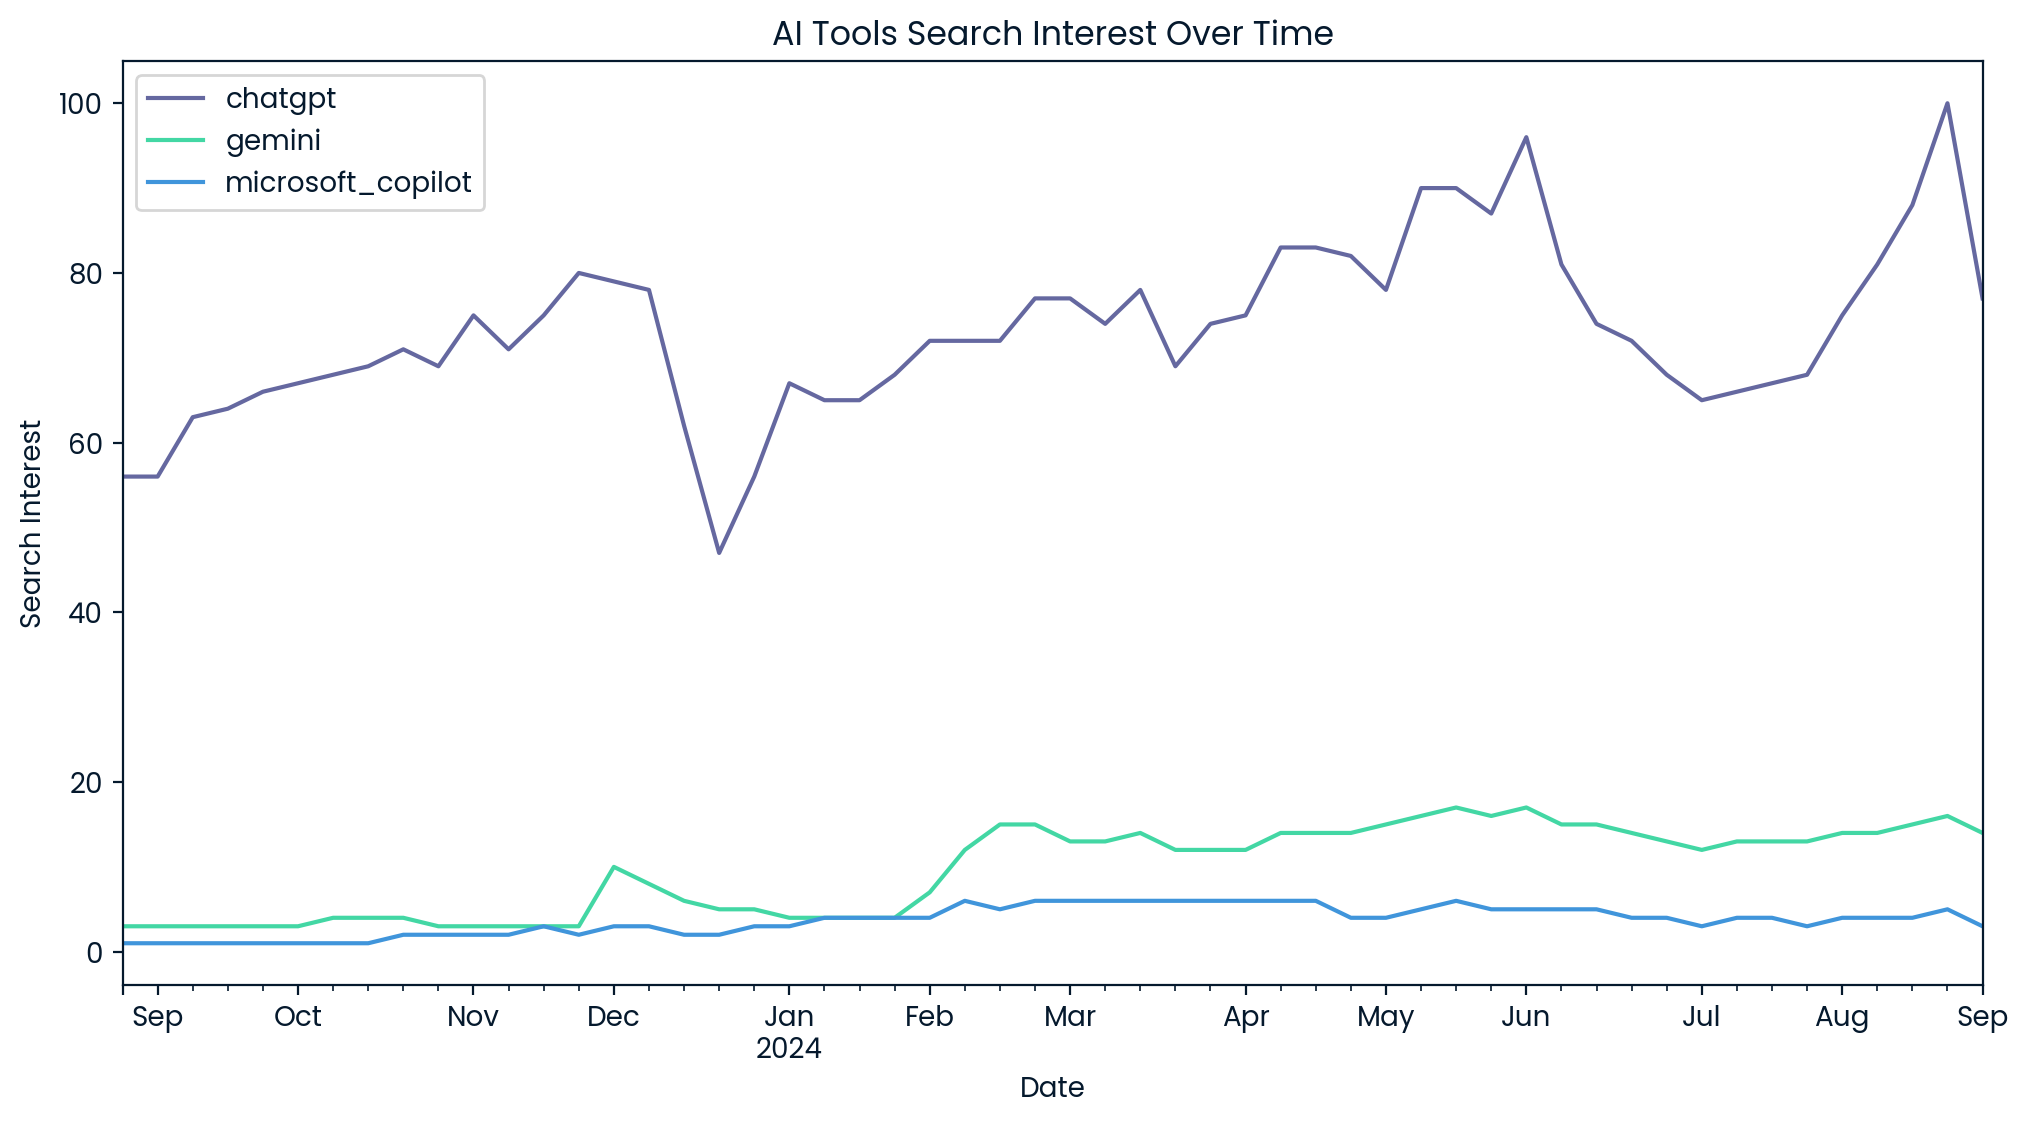

ChatGPT lowest point: December 2023
Most consistent tool: chatgpt
ChatGPT largest dip: December 2023
Best month: May


In [23]:
# Find the AI tool with the most consistent growth
tools = trends.select_dtypes(include="number").columns
growth = trends[tools].iloc[-1] - trends[tools].iloc[0]
most_consistent_tool = growth.idxmax()

# Convert the date column
date_col = trends.columns[0]
trends[date_col] = pd.to_datetime(trends[date_col])
trends = trends.sort_values(date_col)

# Plot interest over time
trends.plot(x=date_col, y=list(tools), figsize=(12, 6))
plt.title("AI Tools Search Interest Over Time")
plt.xlabel("Date")
plt.ylabel("Search Interest")
plt.show()

# Find ChatGPT's largest decline
chatgpt_col = next(c for c in tools if "chatgpt" in c.lower())
dip_index = trends[chatgpt_col].idxmin()
gpt_dip = trends.loc[dip_index, date_col].strftime("%B %Y")

print("ChatGPT lowest point:", gpt_dip)

# Find the month with the highest average interest
trends["Month"] = trends[date_col].dt.month_name()
monthly_avg = trends.groupby("Month")[list(tools)].mean().mean(axis=1)
best_month = monthly_avg.idxmax()

# Display answers
print("Most consistent tool:", most_consistent_tool)
print("ChatGPT largest dip:", gpt_dip)
print("Best month:", best_month)